<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">DATOS MASIVOS II · PRÁCTICA</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Comparación final de los sistemas de recomendación</div><div style="opacity:.72;font-size:14px;margin-top:6px;">Tabla de RMSE en el probe para los modelos de predicción y de Precision@10, Recall@10 y NDCG@10 para los de top-N, tiempos, un ensamble lineal de los predictores y recomendaciones de tres usuarios con cada método.</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Equipo Tres: Castrillo Cruz Karen Arlet, Ramos González Nadia, Zamora Antiga Ángel Javier.</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

### Objetivo

Reunir en un solo lugar los resultados de los notebooks 2 a 5, compararlos con el mismo protocolo y ver
**qué recomienda cada método** a usuarios concretos. Además probamos un ensamble lineal de los predictores de rating,
la técnica con la que se ganó el Netflix Prize (Koren, 2009; Töscher, Jahrer y Bell, 2009).

### Los datos

Las métricas de cada modelo (`data/processed/resultados/*.json`), sus predicciones sobre el probe de S
(`predicciones/`) y sus parámetros (`modelos/`). Este notebook no entrena ningún modelo: solo usa lo guardado.

### Contenido

1. **Tabla comparativa:** predicción (RMSE) y top-N (P@10, R@10, NDCG@10), con tiempos.
2. **Ensamble lineal** de los predictores de rating.
3. **Ejemplos cualitativos:** recomendaciones de tres usuarios con cada método.
4. **Conclusiones y limitaciones.**

In [1]:
# Librerías, rutas, paleta y funciones auxiliares
import json
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import psutil
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display

%matplotlib inline
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 220)

RUTA_PROCESADOS = Path("..") / "data" / "processed"
RUTA_RESULTADOS, RUTA_PREDICCIONES, RUTA_MODELOS = [RUTA_PROCESADOS / c for c in ["resultados", "predicciones", "modelos"]]
SEMILLA = 42
CINEMATCH_PROBE = 0.9474

# Paleta única del notebook: azul principal, rojo de acento y grises neutros
AZUL, ROJO = "#3D6FB0", "#B03D3D"
GRIS, GRIS_CLARO, TINTA = "#8C8C8C", "#EEF1F6", "#333333"

plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": "#999999", "axes.labelcolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA, "legend.frameon": False,
})


def estilo_ejes(ax, titulo=None, xlabel=None, ylabel=None, rejilla="y"):
    # Estilo común de los ejes: título, etiquetas, sin bordes superior y derecho, rejilla tenue
    if titulo:
        ax.set_title(titulo)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    if rejilla:
        ax.grid(axis=rejilla, color="#DDDDDD", linewidth=0.6)
        ax.set_axisbelow(True)


def rmse(pred, real):
    return float(np.sqrt(np.mean((np.clip(pred, 1, 5) - real) ** 2)))


print(f"RAM libre en el sistema: {psutil.virtual_memory().available / 1e9:.2f} GB")

RAM libre en el sistema: 7.88 GB


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">COMPARACIÓN · TABLAS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">1. Tabla comparativa</span></div>



Cada modelo pertenece a una **familia** de métodos del curso. Las métricas son las del protocolo común:

- **RMSE** en el probe completo (solo para los modelos entrenados con los 99 millones de ratings) y en el probe de S
  (262,954 ratings, comparación justa entre todos);
- **P@10, R@10 y NDCG@10** sobre los mismos 5,000 usuarios de S, con las películas del probe calificadas con 4 o 5
  como relevantes.

Recordemos el techo de la P@10: cada usuario evaluado tiene en promedio 2.07 películas relevantes, así que una P@10
perfecta sería 0.207.

In [2]:
# Carga de todos los resultados y asignación de familias
familia = {
    "Popularidad": "referencia", "Baseline (completo)": "referencia", "Baseline (S)": "referencia",
    "kNN ítem-ítem": "vecindario", "kNN ítem-ítem (suma de similitudes)": "vecindario",
    "SVD truncada (completo)": "factorización", "PureSVD (S)": "factorización", "SVD-SGD (S)": "factorización",
    "SVD-SGD (completo)": "factorización", "NMF con máscara (S)": "factorización",
    "Reglas de asociación (S)": "reglas y secuencias", "Reglas de asociación, lift (S)": "reglas y secuencias",
    "PrefixSpan siguiente película (S)": "reglas y secuencias",
    "PageRank global (S)": "grafos", "PageRank personalizado (S)": "grafos",
    "PageRank personalizado, especificidad (S)": "grafos", "Paseo P3 bipartito (S)": "grafos",
    "Contenido TF-IDF (S)": "contenido", "Contenido con factores latentes (S)": "contenido",
    "Híbrido contenido + factores (S)": "contenido",
}
resultados = pd.DataFrame([json.load(open(RUTA_RESULTADOS / f"{m}.json", encoding="utf-8")) for m in familia]).set_index("modelo")
resultados.insert(0, "familia", pd.Series(familia))
COLOR_FAMILIA = {"referencia": GRIS, "vecindario": "#7FA7D9", "factorización": AZUL, "reglas y secuencias": "#D9A066",
                 "grafos": ROJO, "contenido": "#6BAF92"}
faltan = [m for m in familia if not (RUTA_RESULTADOS / f"{m}.json").exists()]
print(f"Modelos: {len(resultados)} | sin resultado: {faltan or 'ninguno'}")

Modelos: 20 | sin resultado: ninguno


,familia,escala,RMSE probe completo,RMSE probe S,mejora sobre el baseline de S,vs. Cinematch (probe completo),entrenamiento (s)
modelo,,,,,,,
SVD-SGD (completo),factorización,completo (99 M),0.9130,0.9043,+7.3 %,-3.6 %,1635.0
SVD-SGD (S),factorización,S,NaN,0.9106,+6.7 %,,338.0
Contenido con factores latentes (S),contenido,S,NaN,0.9298,+4.7 %,,NaN
kNN ítem-ítem,vecindario,S,NaN,0.9312,+4.6 %,,110.0
Híbrido contenido + factores (S),contenido,S,NaN,0.9370,+4.0 %,,NaN
NMF con máscara (S),factorización,S,NaN,0.9470,+3.0 %,,202.0
SVD truncada (completo),factorización,completo (99 M),0.9666,0.9581,+1.8 %,+2.0 %,204.0
Baseline (completo),referencia,completo (99 M),0.9822,0.9753,+0.1 %,+3.7 %,13.0
Baseline (S),referencia,S,NaN,0.9760,+0.0 %,,2.0


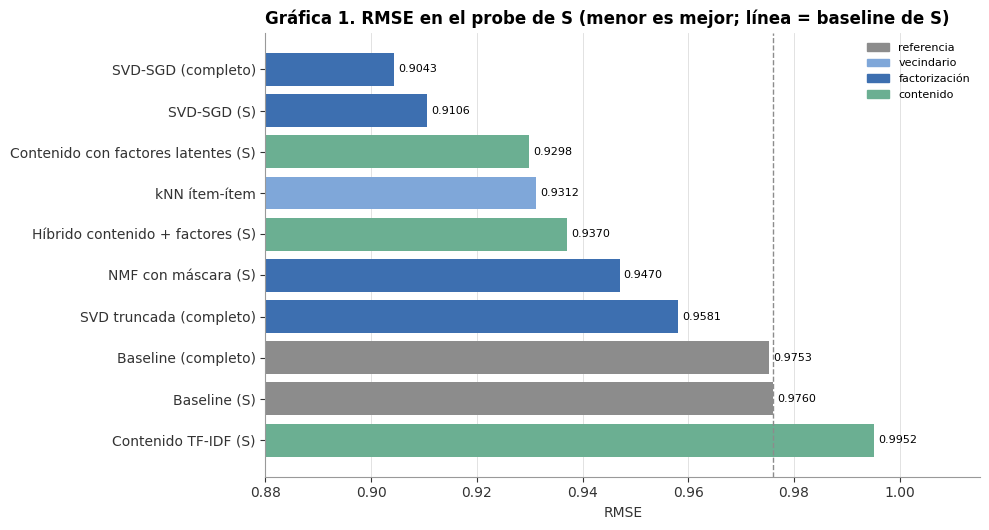

In [3]:
# Tabla y Gráfica 1: modelos de predicción ordenados por RMSE en el probe de S
pred = resultados[resultados["rmse_probe_S"].notna()].sort_values("rmse_probe_S")
base_S = resultados.loc["Baseline (S)", "rmse_probe_S"]
tabla_pred = pd.DataFrame({
    "familia": pred["familia"], "escala": pred["escala"],
    "RMSE probe completo": pred["rmse_probe"],
    "RMSE probe S": pred["rmse_probe_S"],
    "mejora sobre el baseline de S": (1 - pred["rmse_probe_S"] / base_S).map(lambda v: f"{100 * v:+.1f} %"),
    "vs. Cinematch (probe completo)": (pred["rmse_probe"] / CINEMATCH_PROBE - 1).map(lambda v: "" if np.isnan(v) else f"{100 * v:+.1f} %"),
    "entrenamiento (s)": pred["segundos_entrenamiento"].round(0),
})
display(tabla_pred.round(4))

fig, ax = plt.subplots(figsize=(10, 0.42 * len(pred) + 1.2))
barras = ax.barh(pred.index[::-1], pred["rmse_probe_S"][::-1], color=[COLOR_FAMILIA[f] for f in pred["familia"][::-1]])
ax.bar_label(barras, labels=[f"{v:.4f}" for v in pred["rmse_probe_S"][::-1]], fontsize=8, padding=3)
ax.axvline(base_S, color=GRIS, linestyle="--", linewidth=1)
ax.set_xlim(0.88, pred["rmse_probe_S"].max() + 0.02)
ax.legend(handles=[Patch(color=c, label=f) for f, c in COLOR_FAMILIA.items() if f in set(pred["familia"])], fontsize=8,
          loc="upper right")
estilo_ejes(ax, "Gráfica 1. RMSE en el probe de S (menor es mejor; línea = baseline de S)", "RMSE", None, rejilla="x")
plt.tight_layout()
plt.show()

,familia,P@10,R@10,NDCG@10,NDCG@10 / popularidad,tiempo (s),configuración
modelo,,,,,,,
"PageRank personalizado, especificidad (S)",grafos,0.0190,0.0899,0.0573,3.92,59.0,"r_u ln(r_u / r), β = 0.35"
PureSVD (S),factorización,0.0189,0.0915,0.0554,3.79,112.0,"svds de la matriz cruda con ceros, k = 100"
kNN ítem-ítem (suma de similitudes),vecindario,0.0162,0.0780,0.0490,3.35,2.0,suma de similitudes Pearson > 0 con películas calificada...
PageRank personalizado (S),grafos,0.0133,0.0623,0.0379,2.60,59.0,"reinicio en las películas con rating ≥ 4, β = 0.2"
Reglas de asociación (S),reglas y secuencias,0.0103,0.0478,0.0305,2.09,1.0,"pares con s = 2 %, puntaje = máxima confianza"
Paseo P3 bipartito (S),grafos,0.0098,0.0457,0.0276,1.89,36.0,paseo usuario → película → usuario → película
"Reglas de asociación, lift (S)",reglas y secuencias,0.0075,0.0374,0.0241,1.65,1.0,"pares con s = 2 %, puntaje = máximo lift"
PrefixSpan siguiente película (S),reglas y secuencias,0.0077,0.0358,0.0215,1.47,2.0,"reglas a → b con s = 5 %, últimos 3 días del usuario, má..."
Contenido con factores latentes (S),contenido,0.0061,0.0285,0.0181,1.24,11.0,perfil factores latentes (SVD-SGD); RMSE con kNN de cont...


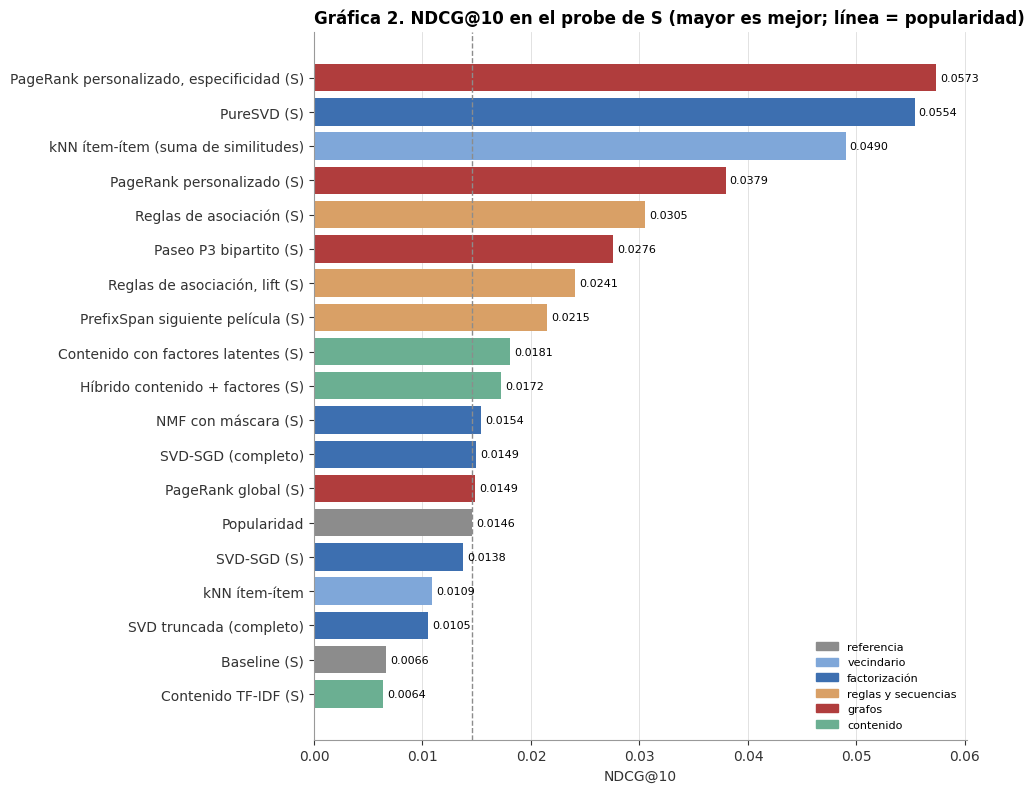

In [4]:
# Tabla y Gráfica 2: modelos de top-N ordenados por NDCG@10
topn = resultados[resultados["NDCG@10"].notna()].sort_values("NDCG@10", ascending=False)
pop = resultados.loc["Popularidad"]
tabla_topn = pd.DataFrame({
    "familia": topn["familia"], "P@10": topn["P@10"], "R@10": topn["R@10"], "NDCG@10": topn["NDCG@10"],
    "NDCG@10 / popularidad": (topn["NDCG@10"] / pop["NDCG@10"]).round(2),
    "tiempo (s)": topn[["segundos_entrenamiento", "segundos_topn"]].sum(axis=1, min_count=1).round(0),
    "configuración": topn["configuracion"].fillna(""),
})
display(tabla_topn.round(4))

fig, ax = plt.subplots(figsize=(10, 0.36 * len(topn) + 1.2))
barras = ax.barh(topn.index[::-1], topn["NDCG@10"][::-1], color=[COLOR_FAMILIA[f] for f in topn["familia"][::-1]])
ax.bar_label(barras, labels=[f"{v:.4f}" for v in topn["NDCG@10"][::-1]], fontsize=8, padding=3)
ax.axvline(pop["NDCG@10"], color=GRIS, linestyle="--", linewidth=1)
ax.legend(handles=[Patch(color=c, label=f) for f, c in COLOR_FAMILIA.items()], fontsize=8, loc="lower right")
estilo_ejes(ax, "Gráfica 2. NDCG@10 en el probe de S (mayor es mejor; línea = popularidad)", "NDCG@10", None, rejilla="x")
plt.tight_layout()
plt.show()

**Observaciones: tabla comparativa**

- **Predicción (Gráfica 1).**
  - El **SVD-SGD** es el mejor predictor: RMSE **0.9130** en el probe completo, **3.6 % mejor que Cinematch**, y
    0.9043 en el probe de S con los 99 millones de ratings. Entrenado solo con S queda en 0.9106.
  - Le siguen el kNN con similitud de **factores latentes** (0.9298) y el **kNN ítem-ítem** de Pearson (0.9312).
  - El orden por familia: factorización por SGD > vecindarios > NMF > SVD con ceros > baseline > contenido.
  - El contenido con TF-IDF del título es el **único** modelo peor que el baseline (0.9952).
  - El SVD-SGD completo y la SVD truncada se entrenaron con los 99 millones de ratings: son los únicos con RMSE
    comparable con Cinematch. Que el SGD completo mejore al de S en el probe de S (0.9043 contra 0.9106) mide lo que
    aportan los datos fuera de la submuestra.
- **Top-N (Gráfica 2).** El podio es de tres familias distintas:
  1. **PageRank personalizado con especificidad** (grafos): NDCG@10 **0.0573**, 3.9 veces la popularidad;
  2. **PureSVD** (factorización): 0.0554, y la mejor R@10 (**0.0915**);
  3. **kNN por suma de similitudes** (vecindario): 0.0490, a una fracción del costo (**2 s** para los 5,000 usuarios).

  Los tres puntúan por **evidencia acumulada** o por **lo no observado**, no por rating predicho.
- **Los mejores predictores de rating son malos ordenando.** SVD-SGD, kNN de rating, SVD truncada y NMF quedan
  alrededor o **debajo de la popularidad** en top-N. El RMSE y el top-N miden cosas distintas (Cremonesi *et al.*,
  2010); por eso el notebook 2 separó los dos puntajes del kNN.
- **Tiempos.** El SVD-SGD completo es el más caro (27 min). Todo lo demás corre en segundos o pocos minutos sobre S.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">COMPARACIÓN · ENSAMBLE</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2. Ensamble lineal de los predictores</span></div>



**Por qué un modelo adicional.** Ningún método del curso combina predictores. Los equipos ganadores del Netflix Prize
mezclaron cientos de modelos con regresiones lineales o *gradient boosting*, porque cada familia se equivoca de forma
distinta (Koren, 2009). Probamos la versión más simple: una **regresión ridge** sobre las predicciones de los modelos
entrenados solo con S,

$$\hat r_{ui} = w_0 + \sum_m w_m\, \hat r^{(m)}_{ui}, \qquad \min_w \lVert y - Xw \rVert^2 + \alpha \lVert w \rVert^2,$$

resuelta en forma cerrada con `numpy`.

**Cómo evitamos evaluar con los datos de ajuste.** No guardamos predicciones sobre la validación, así que ajustamos los
pesos con la mitad de los **usuarios** del probe de S y evaluamos en la otra mitad, y después al revés (validación
cruzada de 2 particiones por usuario). Es lo que hacían los equipos del concurso: mezclaban sobre el probe y
reportaban en el conjunto *quiz*.

In [5]:
# Ensamble ridge con validación cruzada de 2 particiones por usuario sobre el probe de S
S_probe_u, S_probe_r = np.load(RUTA_PROCESADOS / "S_probe_u.npy"), np.load(RUTA_PROCESADOS / "S_probe_r.npy").astype(np.float64)
componentes = {"baseline de S": "baseline_S", "kNN ítem-ítem": "knn_S", "SVD-SGD (S)": "svd_sgd_S", "NMF con máscara": "nmf_S",
               "kNN de contenido": "contenido_tf-idf_S"}
X = np.column_stack([np.load(RUTA_PREDICCIONES / f"{a}.npy").astype(np.float64) for a in componentes.values()])
mitad = np.random.default_rng(SEMILLA).random(S_probe_u.max() + 1) < 0.5
particion = mitad[S_probe_u]


def ridge(X, y, alfa=1.0):
    A = np.column_stack([np.ones(len(X)), X])
    reg = alfa * np.eye(A.shape[1])
    reg[0, 0] = 0
    return np.linalg.solve(A.T @ A + reg, A.T @ y)


pred_ens = np.empty(len(S_probe_r))
pesos = []
for prueba in [particion, ~particion]:
    w = ridge(X[~prueba], S_probe_r[~prueba])
    pred_ens[prueba] = w[0] + X[prueba] @ w[1:]
    pesos.append(w)
np.save(RUTA_PREDICCIONES / "ensamble_S.npy", np.clip(pred_ens, 1, 5).astype(np.float32))
individuales = {m: rmse(X[:, j], S_probe_r) for j, m in enumerate(componentes)}
rmse_ens = rmse(pred_ens, S_probe_r)
display(pd.DataFrame({"RMSE probe S": {**individuales, "ensamble ridge (validación cruzada)": rmse_ens}}).round(4).T)
display(pd.DataFrame(pesos, columns=["intercepto", *componentes], index=["pesos (ajuste en la mitad A)", "pesos (ajuste en la mitad B)"]).round(3))
mejor_individual = min(individuales, key=individuales.get)
print(f"Mejora del ensamble sobre el mejor modelo individual ({mejor_individual}): "
      f"{100 * (1 - rmse_ens / individuales[mejor_individual]):.2f} % | correlación entre los errores de kNN y SVD-SGD: "
      f"{np.corrcoef(X[:, 1] - S_probe_r, X[:, 2] - S_probe_r)[0, 1]:.3f}")
with open(RUTA_RESULTADOS / "Ensamble ridge (S).json", "w", encoding="utf-8") as f:
    json.dump({"modelo": "Ensamble ridge (S)", "tipo": "predicción", "escala": "S", "rmse_probe_S": rmse_ens,
               "configuracion": "ridge α = 1 sobre " + ", ".join(componentes) + "; validación cruzada de 2 particiones por usuario"},
              f, ensure_ascii=False, indent=1)

,baseline de S,kNN ítem-ítem,SVD-SGD (S),NMF con máscara,kNN de contenido,ensamble ridge (validación cruzada)
RMSE probe S,0.976,0.9312,0.9106,0.947,0.9952,0.9059


,intercepto,baseline de S,kNN ítem-ítem,SVD-SGD (S),NMF con máscara,kNN de contenido
pesos (ajuste en la mitad A),0.077,-0.142,0.299,0.650,0.123,0.042
pesos (ajuste en la mitad B),0.092,-0.133,0.324,0.636,0.110,0.032


Mejora del ensamble sobre el mejor modelo individual (SVD-SGD (S)): 0.51 % | correlación entre los errores de kNN y SVD-SGD: 0.957


**Observaciones: ensamble**

- **El ensamble mejora al mejor modelo, pero poco:** RMSE **0.9059** en validación cruzada, contra 0.9106 del SVD-SGD
  de S (**−0.5 %**).
- **Pesos.** Son estables entre las dos particiones: el SVD-SGD aporta ~0.64, el kNN ~0.31, la NMF ~0.12 y el kNN de
  contenido ~0.04. El baseline entra con peso **negativo** (−0.14): corrige el encogimiento hacia la media que ya
  traen los otros modelos.
- **Por qué mejora tan poco.** Los errores del kNN y del SVD-SGD tienen correlación **0.957**: los dos modelos se
  equivocan casi en los mismos ratings. Los ensambles del Netflix Prize ganaban mezclando cientos de modelos con
  información distinta (dinámica temporal, ratings implícitos, RBM), y aun así la mejora final sobre el mejor modelo
  individual fue de pocas centésimas de RMSE.
- **Decisión.** El ensamble es opcional en la práctica y lo dejamos como evidencia de que la combinación aporta. No
  entra a la tabla principal porque se ajusta sobre el mismo probe, aunque sea con validación cruzada por usuario.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">COMPARACIÓN · EJEMPLOS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3. Ejemplos cualitativos</span></div>



Elegimos tres usuarios de la evaluación top-N (semilla 42) con entre 80 y 300 ratings en S y al menos 3 películas
relevantes en el probe. Para cada uno mostramos lo que más le gustó en el entrenamiento, lo que calificó con 4 o 5 en
el probe (lo que "debía" acertarse) y el top-5 de cada método. Las películas marcadas con ✓ están en su probe con
rating ≥ 4. Todos los puntajes se recalculan a partir de los modelos guardados.

In [6]:
# Carga de los modelos guardados y funciones de puntaje para un usuario de S
S_R = sp.load_npz(RUTA_PROCESADOS / "S_R_train.npz")
S_dias = np.load(RUTA_PROCESADOS / "S_dias.npy")
S_peliculas = np.load(RUTA_PROCESADOS / "S_peliculas.npy")
S_probe_m = np.load(RUTA_PROCESADOS / "S_probe_m.npy")
peliculas = pd.read_parquet(RUTA_PROCESADOS / "peliculas.parquet")
titulo = lambda i: f"{peliculas.loc[S_peliculas[i], 'title']} ({peliculas.loc[S_peliculas[i], 'year']})"
n_S_usr, N_PEL = S_R.shape
GUSTA = sp.csr_matrix(((S_R.data >= 4).astype(np.float32), S_R.indices.copy(), S_R.indptr.copy()), shape=S_R.shape)
GUSTA.eliminate_zeros()  # con copias: eliminate_zeros modifica los arreglos en su lugar
popularidad = np.diff(S_R.tocsc().indptr).astype(np.float64)
grado_u = np.diff(GUSTA.indptr)
grado_m = np.asarray(GUSTA.sum(axis=0)).ravel()

SIM = np.maximum(np.load(RUTA_MODELOS / "knn_similitud_S.npy"), 0)
V_pure = np.load(RUTA_MODELOS / "puresvd_V_S.npy")
sgd = np.load(RUTA_MODELOS / "svd_sgd_S.npz")
CONF = sp.load_npz(RUTA_MODELOS / "reglas_confianza_S.npz").toarray()
CONF_SEQ = sp.load_npz(RUTA_MODELOS / "reglas_secuenciales_S.npz").toarray()
W = sp.load_npz(RUTA_MODELOS / "grafo_peliculas_S.npz")
salida = np.asarray(W.sum(axis=1)).ravel()
M = (sp.diags(1 / salida) @ W).T.tocsr().astype(np.float64)
pr = np.load(RUTA_MODELOS / "pagerank_S.npz")
X_cont = sp.load_npz(RUTA_MODELOS / "contenido_S.npz")
media_u = np.asarray(S_R.sum(axis=1)).ravel() / np.maximum(np.diff(S_R.indptr), 1)


def ppr_especificidad(u, beta=float(pr["beta_esp"])):
    v = GUSTA[u].toarray().ravel().astype(np.float64)
    v = v / v.sum() if v.sum() else np.full(N_PEL, 1 / N_PEL)
    r = v.copy()
    for _ in range(1000):
        nuevo = beta * (M @ r) + (1 - beta) * v
        if np.abs(nuevo - r).sum() < 1e-10:
            break
        r = nuevo
    return r * np.log(np.maximum(r, 1e-30) / pr["pr_global"])


def recientes(u):
    a, b = S_R.indptr[u], S_R.indptr[u + 1]
    g = S_R.data[a:b] >= 4
    d = S_dias[a:b][g]
    return S_R.indices[a:b][g][d >= np.unique(d)[-3:].min()] if g.any() else np.zeros(0, int)


def metodos(u):
    g = GUSTA.indices[GUSTA.indptr[u]:GUSTA.indptr[u + 1]]
    fila = S_R[u]
    paso1 = GUSTA[u].toarray().ravel() / max(grado_u[u], 1)
    paso2 = GUSTA @ (paso1 / np.maximum(grado_m, 1))
    paso3 = GUSTA.T @ (paso2 / np.maximum(grado_u, 1))
    centrada = sp.csr_matrix((fila.data - media_u[u], fila.indices, fila.indptr), shape=fila.shape)
    return {
        "popularidad": popularidad,
        "kNN (suma de similitudes)": SIM[g].sum(axis=0),
        "PureSVD": (fila @ V_pure) @ V_pure.T,
        "SVD-SGD (rating predicho)": sgd["mu"] + sgd["bu"][u] + sgd["bi"] + sgd["P"][u] @ sgd["Q"].T,
        "reglas (máx. confianza)": CONF[g].max(axis=0) + 1e-6 * popularidad / popularidad.max(),
        "PrefixSpan (siguiente)": (CONF_SEQ[recientes(u)].max(axis=0) if len(recientes(u)) else 0) + 1e-6 * popularidad / popularidad.max(),
        "PPR (especificidad)": ppr_especificidad(u),
        "P³ bipartito": paso3,
        "contenido (TF-IDF + década)": (X_cont @ (centrada @ X_cont).T).toarray().ravel(),
    }

In [7]:
# Tres usuarios de ejemplo: historial, probe y top-5 de cada método
U_EVAL = np.load(RUTA_PROCESADOS / "S_usuarios_topn.npy")
S_probe_r_int = S_probe_r.astype(int)
rel_por_usuario = pd.Series(S_probe_m[S_probe_r_int >= 4]).groupby(S_probe_u[S_probe_r_int >= 4]).apply(set)
n_train = np.diff(S_R.indptr)
candidatos = [u for u in U_EVAL if 80 <= n_train[u] <= 300 and len(rel_por_usuario.get(u, ())) >= 3]
ejemplos = np.random.default_rng(SEMILLA).choice(candidatos, 3, replace=False)

for u in ejemplos:
    a, b = S_R.indptr[u], S_R.indptr[u + 1]
    historial = pd.DataFrame({"m": S_R.indices[a:b], "rating": S_R.data[a:b].astype(int), "dia": S_dias[a:b]})
    favoritas = historial.sort_values(["rating", "dia"], ascending=False).head(8)
    relevantes = rel_por_usuario[u]
    print(f"Usuario {u} de S: {b - a} ratings en S, rating medio {historial['rating'].mean():.2f}, "
          f"{len(relevantes)} películas relevantes en el probe")
    display(pd.DataFrame({"le gustó (entrenamiento)": [f"{titulo(m)} [{r}]" for m, r in zip(favoritas["m"], favoritas["rating"])],
                          "calificó con 4–5 en el probe": [titulo(m) for m in sorted(relevantes)][:8]
                          + [""] * (8 - min(8, len(relevantes)))}, index=range(1, 9)))
    vistos = set(historial["m"])
    tabla = {}
    for nombre, punt in metodos(u).items():
        punt = np.asarray(punt, dtype=np.float64).ravel().copy()
        punt[list(vistos)] = -np.inf
        top = np.argsort(-punt)[:5]
        tabla[nombre] = [("✓ " if m in relevantes else "") + titulo(m) for m in top]
    display(pd.DataFrame(tabla, index=range(1, 6)).T)

Usuario 62843 de S: 82 ratings en S, rating medio 3.94, 3 películas relevantes en el probe


,le gustó (entrenamiento),calificó con 4–5 en el probe
1,The Last Detail (1973) [5],Airplane II: The Sequel (1982)
2,Rain Man (1988) [5],Finding Nemo (Full-screen) (2003)
3,The Money Pit (1986) [5],Meet the Parents (2000)
4,I Am Sam (2001) [5],
5,Something's Gotta Give (2003) [5],
6,Marty (1955) [5],
7,An Officer and a Gentleman (1982) [5],
8,Twins (1988) [5],


,1,2,3,4,5
popularidad,Miss Congeniality (2000),Independence Day (1996),The Patriot (2000),The Day After Tomorrow (2004),Pretty Woman (1990)
kNN (suma de similitudes),"Good Morning, Vietnam (1987)",City Slickers (1991),Jerry Maguire (1996),Field of Dreams (1989),Rocky (1976)
PureSVD,The Graduate (1967),Pretty Woman (1990),The Terminal (2004),"Good Morning, Vietnam (1987)",The Shining (1980)
SVD-SGD (rating predicho),Schindler's List (1993),The Shawshank Redemption: Special Edition (1994),Lost: Season 1 (2004),Lord of the Rings: The Two Towers: Extended Edition (2002),Lord of the Rings: The Return of the King: Extended Edit...
reglas (máx. confianza),The Shawshank Redemption: Special Edition (1994),The Silence of the Lambs (1991),Pretty Woman (1990),The Sixth Sense (1999),Pulp Fiction (1994)
PrefixSpan (siguiente),The Shawshank Redemption: Special Edition (1994),The Incredibles (2004),Raiders of the Lost Ark (1981),Shrek 2 (2004),Lord of the Rings: The Return of the King (2003)
PPR (especificidad),Erin Brockovich (2000),Sleepless in Seattle (1993),"Good Morning, Vietnam (1987)",Steel Magnolias (1989),Jerry Maguire (1996)
P³ bipartito,The Green Mile (1999),The Shawshank Redemption: Special Edition (1994),The Sixth Sense (1999),Pirates of the Caribbean: The Curse of the Black Pearl (...,Pretty Woman (1990)
contenido (TF-IDF + década),Shane (1953),Auntie Mame (1958),Ikiru (1952),Carousel (1956),Rashomon (1950)


Usuario 9978 de S: 211 ratings en S, rating medio 4.18, 3 películas relevantes en el probe


,le gustó (entrenamiento),calificó con 4–5 en el probe
1,Seabiscuit (2003) [5],Taking Lives (2004)
2,"I, Robot (2004) [5]",50 First Dates (2004)
3,The Bourne Identity (2002) [5],Napoleon Dynamite (2004)
4,Anchorman: The Legend of Ron Burgundy (2004) [5],
5,The Incredibles (2004) [5],
6,Troy (2004) [5],
7,Lord of the Rings: The Return of the King (2003) [5],
8,Hitch (2005) [5],


,1,2,3,4,5
popularidad,The Patriot (2000),The Day After Tomorrow (2004),Pretty Woman (1990),The Green Mile (1999),Forrest Gump (1994)
kNN (suma de similitudes),Happy Gilmore (1996),Big Daddy (1999),✓ 50 First Dates (2004),The Whole Nine Yards (2000),Meet the Parents (2000)
PureSVD,Scarface: 20th Anniversary Edition (1983),Men in Black II (2002),The Bourne Supremacy (2004),Underworld (2003),American History X (1998)
SVD-SGD (rating predicho),South Park: Season 3 (1999),South Park: Season 2 (1998),"South Park: Bigger, Longer and Uncut (1999)",Super Troopers (2002),Family Guy: Vol. 2: Season 3 (2001)
reglas (máx. confianza),The Sixth Sense (1999),The Shawshank Redemption: Special Edition (1994),Forrest Gump (1994),The Usual Suspects (1995),The Green Mile (1999)
PrefixSpan (siguiente),The Lord of the Rings: The Fellowship of the Ring: Exten...,Lord of the Rings: The Return of the King: Extended Edit...,Lord of the Rings: The Two Towers: Extended Edition (2002),National Treasure (2004),The Shawshank Redemption: Special Edition (1994)
PPR (especificidad),Billy Madison (1995),Happy Gilmore (1996),The Rundown (2003),Super Troopers (2002),Big Daddy (1999)
P³ bipartito,The Green Mile (1999),Forrest Gump (1994),The Patriot (2000),Shrek 2 (2004),The Sixth Sense (1999)
contenido (TF-IDF + década),The Guru (2003),The Contender (2000),The Pacifier (2005),The Mothman Prophecies (2002),The Notebook (2004)


Usuario 75694 de S: 134 ratings en S, rating medio 3.50, 3 películas relevantes en el probe


,le gustó (entrenamiento),calificó con 4–5 en el probe
1,A Room with a View: Special Edition (1986) [5],Three Days of the Condor (1975)
2,The Fisher King (1991) [5],Kinsey (2004)
3,The Sweet Hereafter (1997) [5],Klute (1971)
4,Good Will Hunting (1997) [5],
5,Priest (1994) [5],
6,What's Eating Gilbert Grape (1993) [5],
7,Kramer vs. Kramer (1979) [5],
8,The Big Lebowski (1998) [5],


,1,2,3,4,5
popularidad,Miss Congeniality (2000),Independence Day (1996),The Patriot (2000),The Day After Tomorrow (2004),Pirates of the Caribbean: The Curse of the Black Pearl (...
kNN (suma de similitudes),Philadelphia (1993),Edward Scissorhands (1990),Thelma & Louise: Special Edition (1991),The Graduate (1967),Almost Famous (2000)
PureSVD,Lost in Translation (2003),A Beautiful Mind (2001),Love Actually (2003),Monster's Ball (2001),Sleepless in Seattle (1993)
SVD-SGD (rating predicho),The West Wing: Season 1 (1999),Lost in Translation (2003),The West Wing: Season 3 (2001),The Godfather (1972),The Wire: Season 2 (2003)
reglas (máx. confianza),Pulp Fiction (1994),The Shawshank Redemption: Special Edition (1994),The Usual Suspects (1995),Ferris Bueller's Day Off (1986),The Godfather (1972)
PrefixSpan (siguiente),The Shawshank Redemption: Special Edition (1994),The Bourne Supremacy (2004),Raiders of the Lost Ark (1981),Lord of the Rings: The Return of the King: Extended Edit...,Spider-Man 2 (2004)
PPR (especificidad),Lost in Translation (2003),Amadeus (1984),Four Weddings and a Funeral (1994),Shakespeare in Love (1998),Best in Show (2000)
P³ bipartito,Pulp Fiction (1994),Pirates of the Caribbean: The Curse of the Black Pearl (...,The Shawshank Redemption: Special Edition (1994),Lord of the Rings: The Two Towers (2002),Lord of the Rings: The Fellowship of the Ring (2001)
contenido (TF-IDF + década),Porky's (1981),Babette's Feast (1987),Kiki's Delivery Service (1989),Quicksilver (1986),Punchline (1988)


**Observaciones: ejemplos cualitativos**

- **Usuario 62843** (82 ratings; le gustaron *Rain Man*, *Marty*, *An Officer and a Gentleman*, *Twins*). Drama y
  comedia clásicos y adultos.
  - El kNN por suma (*Good Morning, Vietnam*, *City Slickers*, *Jerry Maguire*, *Field of Dreams*) y el PPR con
    especificidad (*Erin Brockovich*, *Sleepless in Seattle*, *Steel Magnolias*) siguen ese perfil.
  - El SVD-SGD recomienda lo **mejor calificado** en general (*Schindler's List*, *Shawshank*, ediciones extendidas de
    *El Señor de los Anillos*).
  - Las reglas, PrefixSpan y P³ recomiendan **éxitos generales** (*Shawshank*, *The Sixth Sense*, *The Incredibles*).
  - El contenido cae en clásicos de los 50 (*Shane*, *Ikiru*, *Rashomon*) solo por la década de *Marty*.
  - Ningún método acierta sus 3 películas del probe (*Airplane II*, *Finding Nemo*, *Meet the Parents*), que no se
    parecen a su historial.
- **Usuario 9978** (211 ratings; *I, Robot*, *Anchorman*, *The Incredibles*, *Hitch*). Comedia y acción recientes.
  - El **kNN por suma acierta** *50 First Dates* en el 3.er lugar, junto a *Happy Gilmore* y *Big Daddy* (Adam
    Sandler, como *50 First Dates*).
  - El PPR con especificidad recomienda el mismo tipo de comedia (*Billy Madison*, *Happy Gilmore*, *Super Troopers*).
  - El SVD-SGD propone *South Park* y *Family Guy*: humor irreverente con rating promedio alto.
- **Usuario 75694** (134 ratings; *A Room with a View*, *The Sweet Hereafter*, *Good Will Hunting*, *The Big
  Lebowski*). Drama independiente y de autor.
  - PureSVD (*Lost in Translation*, *A Beautiful Mind*, *Monster's Ball*), el PPR con especificidad (*Lost in
    Translation*, *Amadeus*, *Shakespeare in Love*) y el SVD-SGD (*The West Wing*, *Lost in Translation*, *The Godfather*,
    *The Wire*) captan el perfil "de autor" del factor 1 del notebook 3.
  - P³ y PrefixSpan vuelven a *El Señor de los Anillos* y *Pirates of the Caribbean*.
- **Patrón general.**
  - La popularidad y los métodos sin corrección de popularidad (reglas, P³, PrefixSpan) dan casi la misma lista a
    todos.
  - Los mejores en top-N (kNN por suma, PureSVD, PPR con especificidad) **personalizan**.
  - El SVD-SGD personaliza, pero hacia lo que el usuario calificaría alto, no hacia lo que vería a continuación.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">COMPARACIÓN · CONCLUSIONES</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4. Conclusiones y limitaciones</span></div>

**Conclusiones**

1. **Con métodos del curso implementados por nosotros superamos a Cinematch.** El SVD con sesgos entrenado por SGD
   (50 factores, ~40 líneas compiladas con `numba`) logra RMSE **0.9130** en el probe, **3.6 % mejor** que el sistema
   de Netflix (0.9474). El baseline de media más sesgos ya queda a 3.7 % de Cinematch: buena parte de la señal está en
   los sesgos de usuario y película.
2. **Lo que decide la factorización es cómo se trata lo no observado.** La misma SVD sirve para predecir si solo usa
   los ratings observados (SGD) o para ordenar si los ceros significan "no la vio" (PureSVD). Con ceros sobre los
   residuos (SVD truncada) no sirve bien para ninguna de las dos.
3. **Predecir y ordenar son tareas distintas.** Los modelos con mejor RMSE recomiendan peor que la popularidad. Los
   mejores recomendadores top-N (PageRank personalizado con especificidad, PureSVD y kNN por suma de similitudes)
   puntúan por evidencia acumulada y **corrigen la popularidad**.
4. **Las técnicas de minería de patrones encuentran estructura con sentido, aunque recomienden menos.**
   - **Factores.** Los dos primeros ejes del gusto (comercial ↔ de autor; romance ↔ acción) reproducen la figura de
     Koren, Bell y Volinsky (2009).
   - **Reglas.** Sus asociaciones más fuertes son sagas.
   - **PageRank.** Encuentra películas "puente".
   - **PrefixSpan.** Muestra que el orden de las calificaciones refleja el calendario de estrenos.
5. **La escala obliga a elegir algoritmos y estructuras.** Los 100 millones de ratings caben en 4 GB solo con tipos
   compactos, CSR y conteos compilados. PCY y sus variantes muestran su valor solo con suficientes cubetas, y A-Priori
   con arreglo triangular gana cuando los pares frecuentes caben en memoria.

**Limitaciones**

- **Submuestra S.** Los métodos que no escalan corren sobre 100,000 usuarios × 5,000 películas, con 18.7 % del probe.
  S excluye el 10.25 % del probe de sus usuarios (películas fuera del top 5,000): las métricas de S no dicen nada de
  las películas poco populares, el caso más difícil.
- **Dinámica temporal.** No modelamos el salto del rating medio de 2004 ni la deriva de los gustos (timeSVD++ de Koren,
  2009). Todos los modelos son estáticos y el probe es casi todo de 2005.
- **Evaluación top-N.** Con ~2 películas relevantes por usuario y las no calificadas tratadas como irrelevantes, las
  métricas absolutas son bajas y favorecen a lo popular. Sirven para comparar modelos entre sí.
- **Metadatos.** Solo hay título y año, así que la recomendación basada en contenido no puede competir. Con metadatos
  reales serviría para el arranque en frío.
- **Fechas.** Son de la calificación, no de la visualización. Por eso los patrones secuenciales aportan poco.
- **Hiperparámetros.** NMF y algunas configuraciones de SGD seguían mejorando al llegar al máximo de iteraciones o
  épocas. Más entrenamiento podría bajar algo su RMSE.